In [1]:
"""
D-RAMZI Photonic KAN for MNIST and Fashion-MNIST.

This notebook follows the paper's two-layer [784, 64, 10] Photonic KAN setup.
Each input-output connection contains its own trainable D-RAMZI edge function;
there is no bank of eight fixed curves and no learned weight for each curve.
The nine physical controls per edge are two MRR phase offsets, two MRR
amplitude transmissions, four MZI phases, and one SOA gain.

Training settings from the supplied article: categorical cross-entropy,
AdamW, learning rate 1e-2, ExponentialLR gamma=0.95, and 30 epochs.
"""

from __future__ import annotations

import csv
import json
import math
import random
import time
from contextlib import nullcontext
from dataclasses import dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, Subset, random_split
from torchvision import datasets, transforms

from dramzi_photonic_kan_model import (
    CarrierDensityLUT,
    DRAMZIKANLayer,
    DRAMZIPhotonicKAN,
    ETA_FC,
    GAMMA_FC,
    LAMBDA0,
    MU,
    NEFF0,
    NG,
    P_MAX,
    RING_LENGTH,
    SOA_GAIN_MAX,
    TAU_FC,
    XI,
    WVG_LENGTHS,
    make_carrier_density_lut,
    steady_state_carrier_density,
)


# Configuração do Teste

### Configuração do experimento

- `SEED` torna a inicialização reproduzível; `DATASETS_TO_RUN` seleciona MNIST e Fashion-MNIST.
- `ARCHITECTURE=(784, 64, 10)` conecta os 784 pixels a 64 nós KAN e depois a 10 classes.
- `EPOCHS=30`, `INITIAL_LR=1e-2` e `LR_GAMMA=0.95` seguem a configuração de treinamento do artigo: AdamW com decaimento exponencial da taxa.
- `BATCH_SIZE` controla quantas imagens são processadas juntas. O valor 64 reduz o pico de memória do cálculo físico por aresta; pode ser aumentado se houver memória de GPU disponível.
- `EDGE_OUTPUT_CHUNK_SIZE` calcula alguns nós de saída por vez para limitar o uso de memória.
- `USE_AMP=False` mantém as operações ópticas complexas em precisão `float32/complex64`.
- `CARRIER_LUT_POINTS` e `CARRIER_LUT_MAX_POWER` configuram a tabela diferenciável da densidade de portadores. Essa tabela acelera a resposta física; ela não é um banco de curvas com pesos treináveis.
- Cada aresta possui nove parâmetros físicos treináveis: duas fases de ressonância dos MRRs, duas transmissões dos MRRs, quatro fases MZI e um ganho SOA.
- `TRAIN_LIMIT` e `TEST_LIMIT` podem limitar os conjuntos para uma execução curta; `None` usa todos os exemplos.


In [2]:
SEED = 42

DATASETS_TO_RUN: Tuple[str, ...] = ("MNIST", "FashionMNIST")

ARCHITECTURE = (784, 64, 10)
EPOCHS = 30
INITIAL_LR = 1e-2
LR_GAMMA = 0.95
WEIGHT_DECAY = 1e-4

# The edge-wise physical model is memory intensive; lower this if CUDA memory is limited.
BATCH_SIZE = 64
TEST_BATCH_SIZE = 256
NUM_WORKERS = 4
USE_AMP = False  # complex-valued optical operations are kept in float32/complex64.
GRAD_CLIP_NORM = 5.0
EDGE_OUTPUT_CHUNK_SIZE = 8
KAN_LOGIT_SCALE = 1.0 / math.sqrt(ARCHITECTURE[1])

CARRIER_LUT_POINTS = 4097
CARRIER_LUT_MAX_POWER = P_MAX * SOA_GAIN_MAX

TRAIN_LIMIT: int | None = None
TEST_LIMIT: int | None = None
VALIDATION_SIZE = 5000
VALIDATE_STEADY_STATE = False

OUTPUT_ROOT = Path("dramzi_photonic_kan_results")
DATA_ROOT = Path("data")


# Definindo Seed e dispositivo usado para treinamento.

1) **set_seed** define manualmente uma semente para os geradores aleatórios (Python, Numpy e PyTorch). Caso tenha GPU disponível, também define a seed.
2) **select_device** é feita uma verificação para ver se o PyTorch consegue ou não usar uma GPU NVidia. Caso não tenha, PyTorch utilizará a CPU como dispositivo padrão.

In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def select_device() -> torch.device:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    print("\n" + "=" * 80)
    print("DEVICE")
    print("=" * 80)
    print(f"PyTorch version: {torch.__version__}")
    print(f"PyTorch CUDA runtime: {torch.version.cuda}")
    print(f"CUDA available: {torch.cuda.is_available()}")
    print(f"Selected device: {device}")

    if device.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}")
        properties = torch.cuda.get_device_properties(0)
        print(f"VRAM: {properties.total_memory / 1024**3:.2f} GB")
        torch.backends.cudnn.benchmark = True
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
    else:
        print(
            "WARNING: this will run on CPU. Install a CUDA-enabled PyTorch "
            "build to use an NVIDIA GPU."
        )

    return device

## Parâmetros físico da unidade D-RAMZI

In [4]:
# Parâmetros ópticos compartilhados com o módulo físico diferenciável.
lambda0 = LAMBDA0
neff0 = NEFF0
ng = NG
L_rr_1 = RING_LENGTH
L_rr_2 = RING_LENGTH
L_wvg1, L_wvg2, L_wvg3, L_wvg4, L_wvg5, L_wvg6 = WVG_LENGTHS

eta_fc = ETA_FC
gamma_fc = GAMMA_FC
mu = MU
tau = TAU_FC
xi = XI

delta_f = 2e9
delta_omega = 2.0 * np.pi * delta_f
P_max = P_MAX


# Modelo óptico diferenciável

O módulo `dramzi_photonic_kan_model.py` implementa as transferências complexas dos MRRs, guias de onda, acopladores, fases MZI e SOA. A célula seguinte mantém a EDO e a solução estacionária usadas para conferir o modelo de portadores.


In [5]:
# As transferências complexas dos MRRs, guias e MZIs são implementadas em
# dramzi_photonic_kan_model.py. A rede chama esse modelo para cada aresta.


# EDO original e Solução Estacionária Algébrica

In [6]:
def carrier_dynamics(t: float, state: np.ndarray, Pin: float, detuning: float) -> List[float]:
    """Equações temporais usadas apenas para validar a solução estacionária."""
    a_real, a_imag, Nc = state
    a_cav = a_real + 1j * a_imag
    intensity = np.abs(a_cav) ** 2

    da_dt = (
        -(1j * detuning + gamma_fc) * a_cav
        - 1j * eta_fc * Nc * a_cav
        - 1j * mu * np.sqrt(Pin)
    )
    dNc_dt = -Nc / tau + xi * intensity**2
    return [float(da_dt.real), float(da_dt.imag), float(dNc_dt)]


def get_Nc_ss_ode(Pin: float, detuning: float = delta_omega) -> float:
    Pin = float(Pin)
    if Pin <= 0.0:
        return 0.0
    solution = solve_ivp(
        lambda t, y: carrier_dynamics(t, y, Pin, detuning),
        (0.0, 100e-9),
        [0.0, 0.0, 0.0],
        rtol=1e-9,
        atol=[1e-20, 1e-20, 1e-14],
        method="DOP853",
    )
    if not solution.success:
        raise RuntimeError(f"Carrier integration failed: {solution.message}")
    return float(solution.y[2, -1])


def get_Nc_ss(Pin: np.ndarray | float, detuning: float = delta_omega):
    """Fast stationary carrier solution used to construct the physical LUT."""
    return steady_state_carrier_density(Pin, detuning=detuning)


def validate_steady_state_solver() -> None:
    print("\n" + "=" * 80)
    print("STEADY-STATE VALIDATION: ALGEBRAIC SOLVER VS ODE")
    print("=" * 80)
    for power in [0.0, 0.05e-3, 0.10e-3, 0.20e-3]:
        algebraic = get_Nc_ss(power)
        ode = get_Nc_ss_ode(power)
        relative_error = abs(algebraic - ode) / max(abs(ode), 1e-30)
        print(
            f"Pin={power:.3e} W | Nc_ODE={ode:.9e} | "
            f"Nc_alg={algebraic:.9e} | relative error={relative_error:.3e}"
        )


## Função física em cada aresta

Cada conexão entrada-saída agora contém um D-RAMZI com controles próprios treináveis. A resposta de uma aresta é calculada pela cascata RAMZI → SOA → RAMZI, usando os parâmetros físicos da própria conexão.


In [7]:
EDGE_PARAMETER_NAMES = (
    "MRR-1 resonance phase",
    "MRR-1 amplitude transmission",
    "MZI-1 phase a",
    "MZI-1 phase b",
    "MRR-2 resonance phase",
    "MRR-2 amplitude transmission",
    "MZI-2 phase a",
    "MZI-2 phase b",
    "SOA gain",
)
print(f"Trainable controls per D-RAMZI edge: {len(EDGE_PARAMETER_NAMES)}")


Trainable controls per D-RAMZI edge: 9


# Tabela da resposta estacionária dos portadores


O artigo usa uma função não linear física em cada aresta. A tabela abaixo contém apenas a resposta estacionária dos portadores em função da potência incidente; ela acelera a avaliação física dentro do PyTorch. As fases dos anéis, perdas, fases MZI e ganho SOA continuam sendo parâmetros independentes e treináveis de cada aresta.


In [8]:
@dataclass
class CarrierDensityTable:
    power_grid: np.ndarray
    carrier_density: np.ndarray

    @property
    def max_power(self) -> float:
        return float(self.power_grid[-1])


def build_carrier_density_table(
    n_points: int = CARRIER_LUT_POINTS,
    max_power: float = CARRIER_LUT_MAX_POWER,
) -> CarrierDensityTable:
    if n_points < 2:
        raise ValueError("CARRIER_LUT_POINTS must be at least 2.")
    power_grid = np.linspace(0.0, max_power, n_points, dtype=np.float64)
    carrier_density = np.asarray(get_Nc_ss(power_grid), dtype=np.float32)
    return CarrierDensityTable(power_grid, carrier_density)


def save_carrier_density_table(table: CarrierDensityTable, output_dir: Path) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    np.save(output_dir / "carrier_power_grid.npy", table.power_grid)
    np.save(output_dir / "carrier_density.npy", table.carrier_density)

    figure, axis = plt.subplots(figsize=(8, 5))
    axis.plot(table.power_grid * 1e3, table.carrier_density, linewidth=2)
    axis.set_xlabel("Input power [mW]")
    axis.set_ylabel("Steady-state carrier density")
    axis.set_title("D-RAMZI carrier-response lookup table")
    axis.grid(True, alpha=0.3)
    figure.tight_layout()
    figure.savefig(output_dir / "carrier_density_lut.png", dpi=200)
    plt.close(figure)


# Camada KAN por arestas físicas


A camada KAN soma as funções univariadas das arestas que chegam ao nó:

$$
y_j = \sum_i \phi_{j,i}(x_i) + b_j.
$$

Cada $\phi_{j,i}$ é um único D-RAMZI com nove controles físicos próprios. O código normaliza a potência de saída pela potência máxima de entrada do D-RAMZI. A primeira soma da KAN é então normalizada por nó e convertida para [0, 1] antes de modular a entrada da próxima camada. A tabela de portadores acelera o cálculo físico; não é um banco de curvas com pesos treináveis.


In [9]:
# CarrierDensityLUT e DRAMZIKANLayer são definidos em dramzi_photonic_kan_model.py.
# Cada camada mantém um D-RAMZI por conexão input-output.


# Camada da KAN

A classe DRAMZIKANLayer implementa a matriz de funções univariadas da KAN. Para uma camada com $n_{in}$ entradas e $n_{out}$ saídas, existem $n_{in}n_{out}$ D-RAMZIs. Cada aresta tem 9 controles treináveis: 6 fases, 2 transmissões de amplitude dos MRRs e o ganho SOA. A camada agrega as saídas das arestas por nó e adiciona um bias por nó.


In [10]:
# A implementação da camada está no módulo importado na primeira célula.


# Camadas da KAN [784, 64, 10]

A rede tem duas camadas de funções de aresta: 784→64→10. A primeira camada soma as respostas físicas de suas arestas. Como a soma precisa voltar ao domínio óptico [0, 1] antes da camada seguinte, aplicamos uma normalização sem parâmetros treináveis e uma sigmoid apenas nessa interface. A segunda camada soma suas funções de aresta e gera os dez logits, com um fator fixo de escala para o classificador.


In [11]:
def build_model(carrier_density_lut: np.ndarray, device: torch.device) -> DRAMZIPhotonicKAN:
    model = DRAMZIPhotonicKAN(
        carrier_density_lut=carrier_density_lut,
        carrier_lut_max_power=CARRIER_LUT_MAX_POWER,
        hidden_features=ARCHITECTURE[1],
        n_classes=ARCHITECTURE[2],
        output_chunk_size=EDGE_OUTPUT_CHUNK_SIZE,
        logit_scale=KAN_LOGIT_SCALE,
    )
    return model.to(device)


# Data Sets e Loaders

* **maybe_limit_dataset** permite usar apenas parte de um conjunto, por exemplo, para fazer um teste rápido. O dataset é o conjunto de imagens, limit é o máximo de imagens a usar e seed é a semente para que a seleção aleatória possa ser repetida.
    * Caso limit seja maior que o dataset ou se for None, ele retorna todo o data set.
    * Caso contrário, o dataset é embaralhado e pega apenas os primeiros elementos (igual a limit). Ela não copia nem modifica o conjunto original.
* **load_dataset** carrega o conjunto escolhido e devolve dois conjuntos separados: treino e teste. Ela ainda não cria os lotes nem treina o modelo. 
* **split_train_validation** é uma parte do treino. Uma parte dos sets de treinamento são usados para acompanhar o modelo.
* **make_loaders** é a função que organiza todo o preparo dos dados para o treinamento. load_dataset carrega MNIST ou Fashion-MNIST. split_train_validation separa treino de validação. Ela não treina a rede, apenas prepara os dados para que o código de treinamento possa percorrê-los em lotes. A validação está incluída porque o restante do código espera receber esse terceiro conjunto.

In [12]:
def maybe_limit_dataset(dataset: Dataset, limit: int | None, seed: int) -> Dataset:
    if limit is None or limit >= len(dataset):
        return dataset
    generator = torch.Generator().manual_seed(seed)
    indices = torch.randperm(len(dataset), generator=generator)[:limit].tolist()
    return Subset(dataset, indices)


def load_dataset(name: str) -> Tuple[Dataset, Dataset]:
    transform = transforms.ToTensor()

    if name == "MNIST":
        train_full = datasets.MNIST(
            root=str(DATA_ROOT), train=True, download=True, transform=transform
        )
        test_set = datasets.MNIST(
            root=str(DATA_ROOT), train=False, download=True, transform=transform
        )
    elif name == "FashionMNIST":
        train_full = datasets.FashionMNIST(
            root=str(DATA_ROOT), train=True, download=True, transform=transform
        )
        test_set = datasets.FashionMNIST(
            root=str(DATA_ROOT), train=False, download=True, transform=transform
        )
    else:
        raise ValueError(f"Unsupported dataset: {name}")

    return (
        maybe_limit_dataset(train_full, TRAIN_LIMIT, SEED),
        maybe_limit_dataset(test_set, TEST_LIMIT, SEED + 1),
    )


def split_train_validation(dataset: Dataset) -> Tuple[Dataset, Dataset]:
    validation_size = min(VALIDATION_SIZE, max(len(dataset) // 10, 1))
    train_size = len(dataset) - validation_size
    if train_size <= 0:
        raise ValueError("Dataset is too small for the requested validation split.")

    generator = torch.Generator().manual_seed(SEED)
    return random_split(dataset, [train_size, validation_size], generator=generator)


def make_loaders(
    dataset_name: str,
    device: torch.device,
) -> Tuple[DataLoader, DataLoader, DataLoader]:
    train_full, test_set = load_dataset(dataset_name)
    train_set, validation_set = split_train_validation(train_full)

    loader_kwargs = {
        "num_workers": NUM_WORKERS,
        "pin_memory": device.type == "cuda",
        "persistent_workers": NUM_WORKERS > 0,
    }

    train_loader = DataLoader(
        train_set,
        batch_size=BATCH_SIZE,
        shuffle=True,
        drop_last=False, #o ultimo lote tambem eh usado mesmo que seja menor que batch_size
        **loader_kwargs,
    )
    validation_loader = DataLoader(
        validation_set,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        drop_last=False, #o ultimo lote tambem eh usado mesmo que seja menor que batch_size
        **loader_kwargs,
    )
    test_loader = DataLoader(
        test_set,
        batch_size=TEST_BATCH_SIZE,
        shuffle=False,
        drop_last=False, #o ultimo lote tambem eh usado mesmo que seja menor que batch_size
        **loader_kwargs,
    )

    print(
        f"{dataset_name}: train={len(train_set)}, "
        f"validation={len(validation_set)}, test={len(test_set)}"
    )
    return train_loader, validation_loader, test_loader


# Training Utilities

* **EpochMetrics** guarda informações de treinamento em uma época. Época, Taxa de aprendizado, Loss do treino, precisão do treino, loss da validação, precisão da validação, loss do teste, precisão do teste e segundos.
* **autocast_context** usa precisão mista caso USE_AMP seja True e se o dispositivo usado for cuda. A precisão mista permite acelerar o treinamento. Como não estou usando cuda, então os cálculos seguem normalmente. 
* **make_grad_scaler** segue os mesmos critérios de **autocast_context**. Durante a precisão mista, os gradientes podem ficar instáveis. Para evitar instabilidade, é criado um GradScaler.
* **accuracy_count** conta quantas previsões foram feitas corretamente. Se foram mostradas 5 imagens, e 4 tiveram previsões corretas, então a função retorna 4. 

In [13]:
@dataclass
class EpochMetrics:
    epoch: int
    learning_rate: float
    train_loss: float
    train_accuracy: float
    validation_loss: float
    validation_accuracy: float
    test_loss: float
    test_accuracy: float
    seconds: float


def autocast_context(device: torch.device):
    if USE_AMP and device.type == "cuda":
        return torch.autocast(device_type="cuda", dtype=torch.float16)
    return nullcontext()


def make_grad_scaler(device: torch.device):
    enabled = USE_AMP and device.type == "cuda"
    try:
        return torch.amp.GradScaler("cuda", enabled=enabled)
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler(enabled=enabled)


def accuracy_count(logits: torch.Tensor, labels: torch.Tensor) -> int:
    return int((logits.argmax(dim=1) == labels).sum().item())


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    scaler,
    device: torch.device,
) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with autocast_context(device):
            logits = model(images)
            loss = F.cross_entropy(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()

        batch_size = labels.shape[0]
        total_loss += float(loss.item()) * batch_size
        total_correct += accuracy_count(logits.detach(), labels)
        total_examples += batch_size

    return total_loss / total_examples, total_correct / total_examples


@torch.no_grad()
def evaluate(
    model: nn.Module,
    loader: DataLoader,
    device: torch.device,
) -> Tuple[float, float, np.ndarray]:
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    confusion = np.zeros((10, 10), dtype=np.int64)

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast_context(device):
            logits = model(images)
            loss = F.cross_entropy(logits, labels)

        predictions = logits.argmax(dim=1)
        batch_size = labels.shape[0]

        total_loss += float(loss.item()) * batch_size
        total_correct += int((predictions == labels).sum().item())
        total_examples += batch_size

        true_np = labels.cpu().numpy()
        pred_np = predictions.cpu().numpy()
        np.add.at(confusion, (true_np, pred_np), 1)

    return (
        total_loss / total_examples,
        total_correct / total_examples,
        confusion,
    )


def count_parameters(model: nn.Module) -> int:
    return sum(parameter.numel() for parameter in model.parameters())


def save_history_csv(history: Sequence[EpochMetrics], path: Path) -> None:
    with path.open("w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow(
            [
                "epoch",
                "learning_rate",
                "train_loss",
                "train_accuracy",
                "validation_loss",
                "validation_accuracy",
                "test_loss",
                "test_accuracy",
                "seconds",
            ]
        )
        for item in history:
            writer.writerow(
                [
                    item.epoch,
                    item.learning_rate,
                    item.train_loss,
                    item.train_accuracy,
                    item.validation_loss,
                    item.validation_accuracy,
                    item.test_loss,
                    item.test_accuracy,
                    item.seconds,
                ]
            )


def load_checkpoint(path: Path, device: torch.device) -> dict:
    try:
        return torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        return torch.load(path, map_location=device)



In [14]:

# ============================================================================
# 13. PLOTS
# ============================================================================


def plot_dataset_history(
    dataset_name: str,
    history: Sequence[EpochMetrics],
    output_dir: Path,
) -> None:
    epochs = np.array([item.epoch for item in history])
    train_loss = np.array([item.train_loss for item in history])
    validation_loss = np.array([item.validation_loss for item in history])
    test_loss = np.array([item.test_loss for item in history])
    train_accuracy = np.array([item.train_accuracy for item in history])
    validation_accuracy = np.array([item.validation_accuracy for item in history])
    test_accuracy = np.array([item.test_accuracy for item in history])

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, train_loss, linewidth=2, label="Train")
    plt.plot(epochs, validation_loss, linewidth=2, label="Validation")
    plt.plot(epochs, test_loss, linewidth=2, label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy loss")
    plt.yscale("log")
    plt.title(f"{dataset_name} - loss")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "loss.png", dpi=200)
    plt.close()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, 100.0 * train_accuracy, linewidth=2, label="Train")
    plt.plot(epochs, 100.0 * validation_accuracy, linewidth=2, label="Validation")
    plt.plot(epochs, 100.0 * test_accuracy, linewidth=2, label="Test")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy [%]")
    plt.title(f"{dataset_name} - accuracy")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(output_dir / "accuracy.png", dpi=200)
    plt.close()

    # A curve resembling the supplied figure: test accuracy and test loss.
    figure, accuracy_axis = plt.subplots(figsize=(8, 5))
    loss_axis = accuracy_axis.twinx()

    accuracy_line = accuracy_axis.plot(
        epochs, test_accuracy, linewidth=2, label="Accuracy"
    )[0]
    loss_line = loss_axis.plot(epochs, test_loss, linewidth=2, label="Loss")[0]

    accuracy_axis.set_xlabel("Epoch")
    accuracy_axis.set_ylabel("Accuracy")
    loss_axis.set_ylabel("Loss")
    accuracy_axis.set_title(dataset_name)
    accuracy_axis.grid(True)
    accuracy_axis.legend(
        [accuracy_line, loss_line], ["Accuracy", "Loss"], loc="best"
    )

    final_start = max(len(epochs) - 20, 0)
    inset = accuracy_axis.inset_axes([0.54, 0.48, 0.42, 0.42])
    inset_loss = inset.twinx()
    inset.plot(epochs[final_start:], test_accuracy[final_start:], linewidth=1.2)
    inset_loss.plot(epochs[final_start:], test_loss[final_start:], linewidth=1.2)
    inset.tick_params(labelsize=7)
    inset_loss.tick_params(labelsize=7)
    inset.grid(True)

    figure.tight_layout()
    figure.savefig(output_dir / "paper_style_curve.png", dpi=220)
    plt.close(figure)


def plot_confusion_matrix(
    confusion: np.ndarray,
    dataset_name: str,
    output_path: Path,
) -> None:
    row_sum = np.maximum(confusion.sum(axis=1, keepdims=True), 1)
    normalized = confusion / row_sum

    plt.figure(figsize=(7, 6))
    plt.imshow(normalized, origin="upper", aspect="auto", vmin=0.0, vmax=1.0)
    plt.colorbar(label="Fraction")
    plt.xlabel("Predicted class")
    plt.ylabel("True class")
    plt.title(f"{dataset_name} - normalized confusion matrix")
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.tight_layout()
    plt.savefig(output_path, dpi=200)
    plt.close()


def plot_combined_paper_figure(
    histories: Dict[str, Sequence[EpochMetrics]],
    output_path: Path,
) -> None:
    names = list(histories.keys())
    if not names:
        return

    figure, axes = plt.subplots(1, len(names), figsize=(7 * len(names), 5))
    if len(names) == 1:
        axes = [axes]

    for panel_index, (axis, name) in enumerate(zip(axes, names)):
        history = histories[name]
        epochs = np.array([item.epoch for item in history])
        accuracy = np.array([item.test_accuracy for item in history])
        loss = np.array([item.test_loss for item in history])

        loss_axis = axis.twinx()
        accuracy_line = axis.plot(
            epochs, accuracy, linewidth=2, label="Accuracy"
        )[0]
        loss_line = loss_axis.plot(epochs, loss, linewidth=2, label="Loss")[0]

        axis.set_xlabel("Epoch")
        axis.set_ylabel("Accuracy")
        loss_axis.set_ylabel("Loss")
        axis.set_title(f"({chr(97 + panel_index)}) {name}")
        axis.grid(True)
        axis.legend(
            [accuracy_line, loss_line],
            ["Accuracy", "Loss"],
            loc="lower right",
        )

        final_start = max(len(epochs) - 20, 0)
        inset = axis.inset_axes([0.50, 0.48, 0.46, 0.42])
        inset_loss = inset.twinx()
        inset.plot(epochs[final_start:], accuracy[final_start:], linewidth=1.0)
        inset_loss.plot(epochs[final_start:], loss[final_start:], linewidth=1.0)
        inset.tick_params(labelsize=7)
        inset_loss.tick_params(labelsize=7)
        inset.grid(True)

    figure.suptitle("D-RAMZI-based Photonic KAN")
    figure.tight_layout()
    figure.savefig(output_path, dpi=220)
    plt.close(figure)


def plot_sample_edge_functions(
    model: DRAMZIPhotonicKAN,
    dataset_name: str,
    output_dir: Path,
    device: torch.device,
) -> None:
    """Save learned physical responses from individual KAN edges."""
    x_values = torch.linspace(0.0, 1.0, 256, device=device)
    layer_specs = (
        (model.layer1, 0, [0, 150, 300, 450, 650, 783], "784 → 64"),
        (model.layer2, 0, list(range(min(6, model.layer2.in_features))), "64 → 10"),
    )
    for layer_number, (layer, output_index, input_indices, architecture_label) in enumerate(
        layer_specs, start=1
    ):
        figure, axis = plt.subplots(figsize=(8, 5))
        with torch.no_grad():
            for input_index in input_indices:
                curve = layer.response_curve(
                    x_values,
                    output_index=output_index,
                    input_index=input_index,
                    carrier_lut=model.carrier_lut,
                )
                axis.plot(
                    x_values.cpu().numpy(),
                    curve.cpu().numpy(),
                    linewidth=1.6,
                    label=f"input edge {input_index}",
                )
        axis.set_xlabel("Normalized input to edge")
        axis.set_ylabel("Normalized D-RAMZI output power")
        axis.set_title(f"{dataset_name}: learned edge functions ({architecture_label})")
        axis.grid(True, alpha=0.3)
        axis.legend(ncol=2)
        figure.tight_layout()
        figure.savefig(
            output_dir / f"learned_edge_functions_layer{layer_number}.png",
            dpi=200,
        )
        plt.close(figure)


# ============================================================================
# 14. TRAIN ONE DATASET
# ============================================================================


def train_dataset(
    dataset_name: str,
    carrier_density_lut: np.ndarray,
    device: torch.device,
) -> Tuple[List[EpochMetrics], Dict[str, float]]:
    output_dir = OUTPUT_ROOT / dataset_name
    output_dir.mkdir(parents=True, exist_ok=True)

    train_loader, validation_loader, test_loader = make_loaders(
        dataset_name, device
    )

    model = build_model(carrier_density_lut, device)

    print("\n" + "=" * 80)
    print(f"TRAINING {dataset_name}")
    print("=" * 80)
    print(f"Architecture: {ARCHITECTURE}")
    print(f"Trainable parameters: {count_parameters(model):,}")
    n_edges = (
        model.layer1.in_features * model.layer1.out_features
        + model.layer2.in_features * model.layer2.out_features
    )
    print(f"Trainable D-RAMZI edges: {n_edges:,}")
    print("Trainable physical controls per edge: 9")
    print(f"Carrier LUT points: {carrier_density_lut.size:,}")
    print(f"AdamW initial lr: {INITIAL_LR:.3e}")
    print(f"AdamW weight decay: {WEIGHT_DECAY:.3e}")
    print(f"ExponentialLR gamma: {LR_GAMMA}")
    print(f"Epochs: {EPOCHS}")

    optimizer = torch.optim.AdamW(
        model.parameters(), lr=INITIAL_LR, weight_decay=WEIGHT_DECAY
    )
    scheduler = torch.optim.lr_scheduler.ExponentialLR(
        optimizer, gamma=LR_GAMMA
    )
    scaler = make_grad_scaler(device)

    history: List[EpochMetrics] = []
    best_validation_accuracy = -np.inf
    best_epoch = 0
    best_checkpoint_path = output_dir / "best_validation_model.pt"

    for epoch in range(1, EPOCHS + 1):
        epoch_start = time.perf_counter()
        current_lr = float(optimizer.param_groups[0]["lr"])

        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, optimizer, scaler, device
        )
        validation_loss, validation_accuracy, _ = evaluate(
            model, validation_loader, device
        )
        test_loss, test_accuracy, _ = evaluate(model, test_loader, device)

        elapsed = time.perf_counter() - epoch_start
        metrics = EpochMetrics(
            epoch=epoch,
            learning_rate=current_lr,
            train_loss=train_loss,
            train_accuracy=train_accuracy,
            validation_loss=validation_loss,
            validation_accuracy=validation_accuracy,
            test_loss=test_loss,
            test_accuracy=test_accuracy,
            seconds=elapsed,
        )
        history.append(metrics)

        if validation_accuracy > best_validation_accuracy:
            best_validation_accuracy = validation_accuracy
            best_epoch = epoch
            torch.save(
                {
                    "dataset": dataset_name,
                    "epoch": epoch,
                    "architecture": ARCHITECTURE,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "validation_accuracy": validation_accuracy,
                    "test_accuracy_at_checkpoint": test_accuracy,
                },
                best_checkpoint_path,
            )

        scheduler.step()

        print(
            f"Epoch {epoch:02d}/{EPOCHS} | "
            f"train loss={train_loss:.5f} acc={100*train_accuracy:6.2f}% | "
            f"val loss={validation_loss:.5f} acc={100*validation_accuracy:6.2f}% | "
            f"test loss={test_loss:.5f} acc={100*test_accuracy:6.2f}% | "
            f"lr={current_lr:.3e} | {elapsed:.1f}s"
        )

    torch.save(
        {
            "dataset": dataset_name,
            "epoch": EPOCHS,
            "architecture": ARCHITECTURE,
            "model_state_dict": model.state_dict(),
        },
        output_dir / "final_model.pt",
    )

    final_test_loss, final_test_accuracy, final_confusion = evaluate(
        model, test_loader, device
    )

    best_checkpoint = load_checkpoint(best_checkpoint_path, device)
    model.load_state_dict(best_checkpoint["model_state_dict"])
    plot_sample_edge_functions(model, dataset_name, output_dir, device)
    best_test_loss, best_test_accuracy, best_confusion = evaluate(
        model, test_loader, device
    )

    save_history_csv(history, output_dir / "history.csv")
    plot_dataset_history(dataset_name, history, output_dir)
    plot_confusion_matrix(
        best_confusion,
        dataset_name,
        output_dir / "best_validation_confusion_matrix.png",
    )
    plot_confusion_matrix(
        final_confusion,
        dataset_name,
        output_dir / "final_confusion_matrix.png",
    )

    summary = {
        "dataset": dataset_name,
        "architecture": list(ARCHITECTURE),
        "epochs": EPOCHS,
        "optimizer": "AdamW",
        "initial_learning_rate": INITIAL_LR,
        "lr_gamma": LR_GAMMA,
        "weight_decay": WEIGHT_DECAY,
        "model_type": "edgewise_trainable_dramzi_kan",
        "trainable_dramzi_edges": int(n_edges),
        "trainable_physical_controls_per_edge": 9,
        "carrier_lut_points": int(carrier_density_lut.size),
        "carrier_lut_max_power_w": CARRIER_LUT_MAX_POWER,
        "output_chunk_size": EDGE_OUTPUT_CHUNK_SIZE,
        "logit_scale": KAN_LOGIT_SCALE,
        "trainable_parameters": count_parameters(model),
        "best_validation_epoch": best_epoch,
        "best_validation_accuracy": float(best_validation_accuracy),
        "test_accuracy_at_best_validation": float(best_test_accuracy),
        "test_loss_at_best_validation": float(best_test_loss),
        "final_test_accuracy": float(final_test_accuracy),
        "final_test_loss": float(final_test_loss),
    }

    with (output_dir / "summary.json").open("w") as file:
        json.dump(summary, file, indent=2)

    print("\n" + "-" * 80)
    print(f"{dataset_name} SUMMARY")
    print("-" * 80)
    print(f"Best validation epoch: {best_epoch}")
    print(f"Best validation accuracy: {100*best_validation_accuracy:.2f}%")
    print(
        "Test accuracy at best validation checkpoint: "
        f"{100*best_test_accuracy:.2f}%"
    )
    print(f"Final test accuracy: {100*final_test_accuracy:.2f}%")

    return history, summary


# ============================================================================
# 15. MAIN
# ============================================================================


def main() -> None:
    set_seed(SEED)
    device = select_device()
    OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

    if VALIDATE_STEADY_STATE:
        validate_steady_state_solver()

    carrier_table = build_carrier_density_table()
    save_carrier_density_table(carrier_table, OUTPUT_ROOT / "physical_response")

    configuration = {
        "seed": SEED,
        "datasets": list(DATASETS_TO_RUN),
        "architecture": list(ARCHITECTURE),
        "epochs": EPOCHS,
        "initial_lr": INITIAL_LR,
        "lr_gamma": LR_GAMMA,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "test_batch_size": TEST_BATCH_SIZE,
        "model_type": "edgewise_trainable_dramzi_kan",
        "edge_parameter_names": list(EDGE_PARAMETER_NAMES),
        "trainable_physical_controls_per_edge": 9,
        "carrier_lut_points": CARRIER_LUT_POINTS,
        "carrier_lut_max_power_w": CARRIER_LUT_MAX_POWER,
        "output_chunk_size": EDGE_OUTPUT_CHUNK_SIZE,
        "logit_scale": KAN_LOGIT_SCALE,
        "mrr_attenuation_bounds": [0.70, 0.99],
        "soa_gain_bounds": [1.0, 20.0],
    }
    with (OUTPUT_ROOT / "configuration.json").open("w") as file:
        json.dump(configuration, file, indent=2)

    all_histories: Dict[str, Sequence[EpochMetrics]] = {}
    all_summaries: Dict[str, Dict[str, float]] = {}

    for dataset_name in DATASETS_TO_RUN:
        # Fresh model and deterministic initialization for each dataset.
        set_seed(SEED)
        history, summary = train_dataset(
            dataset_name,
            carrier_table.carrier_density,
            device,
        )
        all_histories[dataset_name] = history
        all_summaries[dataset_name] = summary

        if device.type == "cuda":
            torch.cuda.empty_cache()

    plot_combined_paper_figure(
        all_histories,
        OUTPUT_ROOT / "MNIST_FashionMNIST_paper_style.png",
    )

    with (OUTPUT_ROOT / "all_results.json").open("w") as file:
        json.dump(all_summaries, file, indent=2)

    print("\n" + "=" * 80)
    print("EXPERIMENT COMPLETED")
    print("=" * 80)
    print(f"Results saved in: {OUTPUT_ROOT.resolve()}")


if __name__ == "__main__":
    main()



DEVICE
PyTorch version: 2.14.0+cu132
PyTorch CUDA runtime: 13.2
CUDA available: True
Selected device: cuda
GPU: NVIDIA GeForce RTX 4060
VRAM: 8.00 GB
MNIST: train=55000, validation=5000, test=10000

TRAINING MNIST
Architecture: (784, 64, 10)
Trainable parameters: 457,418
Trainable D-RAMZI edges: 50,816
Trainable physical controls per edge: 9
Carrier LUT points: 4,097
AdamW initial lr: 1.000e-02
AdamW weight decay: 1.000e-04
ExponentialLR gamma: 0.95
Epochs: 30
Epoch 01/30 | train loss=0.85822 acc= 84.18% | val loss=0.61693 acc= 87.28% | test loss=0.59284 acc= 88.01% | lr=1.000e-02 | 39.4s
Epoch 02/30 | train loss=0.55101 acc= 89.01% | val loss=0.52453 acc= 88.58% | test loss=0.50365 acc= 89.74% | lr=9.500e-03 | 29.1s
Epoch 03/30 | train loss=0.50778 acc= 89.54% | val loss=0.50674 acc= 88.88% | test loss=0.49114 acc= 90.15% | lr=9.025e-03 | 29.2s
Epoch 04/30 | train loss=0.49337 acc= 89.57% | val loss=0.50859 acc= 88.82% | test loss=0.48924 acc= 89.52% | lr=8.574e-03 | 29.2s
Epoch 05/3

C:\Users\gson5\AppData\Local\Temp\ipykernel_47060\1326846590.py:73: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()



--------------------------------------------------------------------------------
MNIST SUMMARY
--------------------------------------------------------------------------------
Best validation epoch: 30
Best validation accuracy: 90.48%
Test accuracy at best validation checkpoint: 91.11%
Final test accuracy: 91.11%
FashionMNIST: train=55000, validation=5000, test=10000

TRAINING FashionMNIST
Architecture: (784, 64, 10)
Trainable parameters: 457,418
Trainable D-RAMZI edges: 50,816
Trainable physical controls per edge: 9
Carrier LUT points: 4,097
AdamW initial lr: 1.000e-02
AdamW weight decay: 1.000e-04
ExponentialLR gamma: 0.95
Epochs: 30
Epoch 01/30 | train loss=0.86134 acc= 76.81% | val loss=0.68775 acc= 80.86% | test loss=0.69385 acc= 79.72% | lr=1.000e-02 | 41.2s
Epoch 02/30 | train loss=0.62017 acc= 81.85% | val loss=0.62284 acc= 81.30% | test loss=0.62599 acc= 80.96% | lr=9.500e-03 | 29.6s
Epoch 03/30 | train loss=0.59071 acc= 82.33% | val loss=0.60919 acc= 82.24% | test loss=0.610

C:\Users\gson5\AppData\Local\Temp\ipykernel_47060\1326846590.py:144: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  figure.tight_layout()



EXPERIMENT COMPLETED
Results saved in: C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results


PyTorch: 2.14.0+cu132
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4060
Loaded checkpoint: C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results\FashionMNIST\best_validation_model.pt
Checkpoint epoch: 30

PREDICTION VISUALIZATION: FashionMNIST
Checkpoint: best
Test examples: 10000
Correct: 8388
Incorrect: 1612
Recomputed test accuracy: 83.88%
Note: the maximum softmax score is a model confidence score; it is not automatically a calibrated probability.


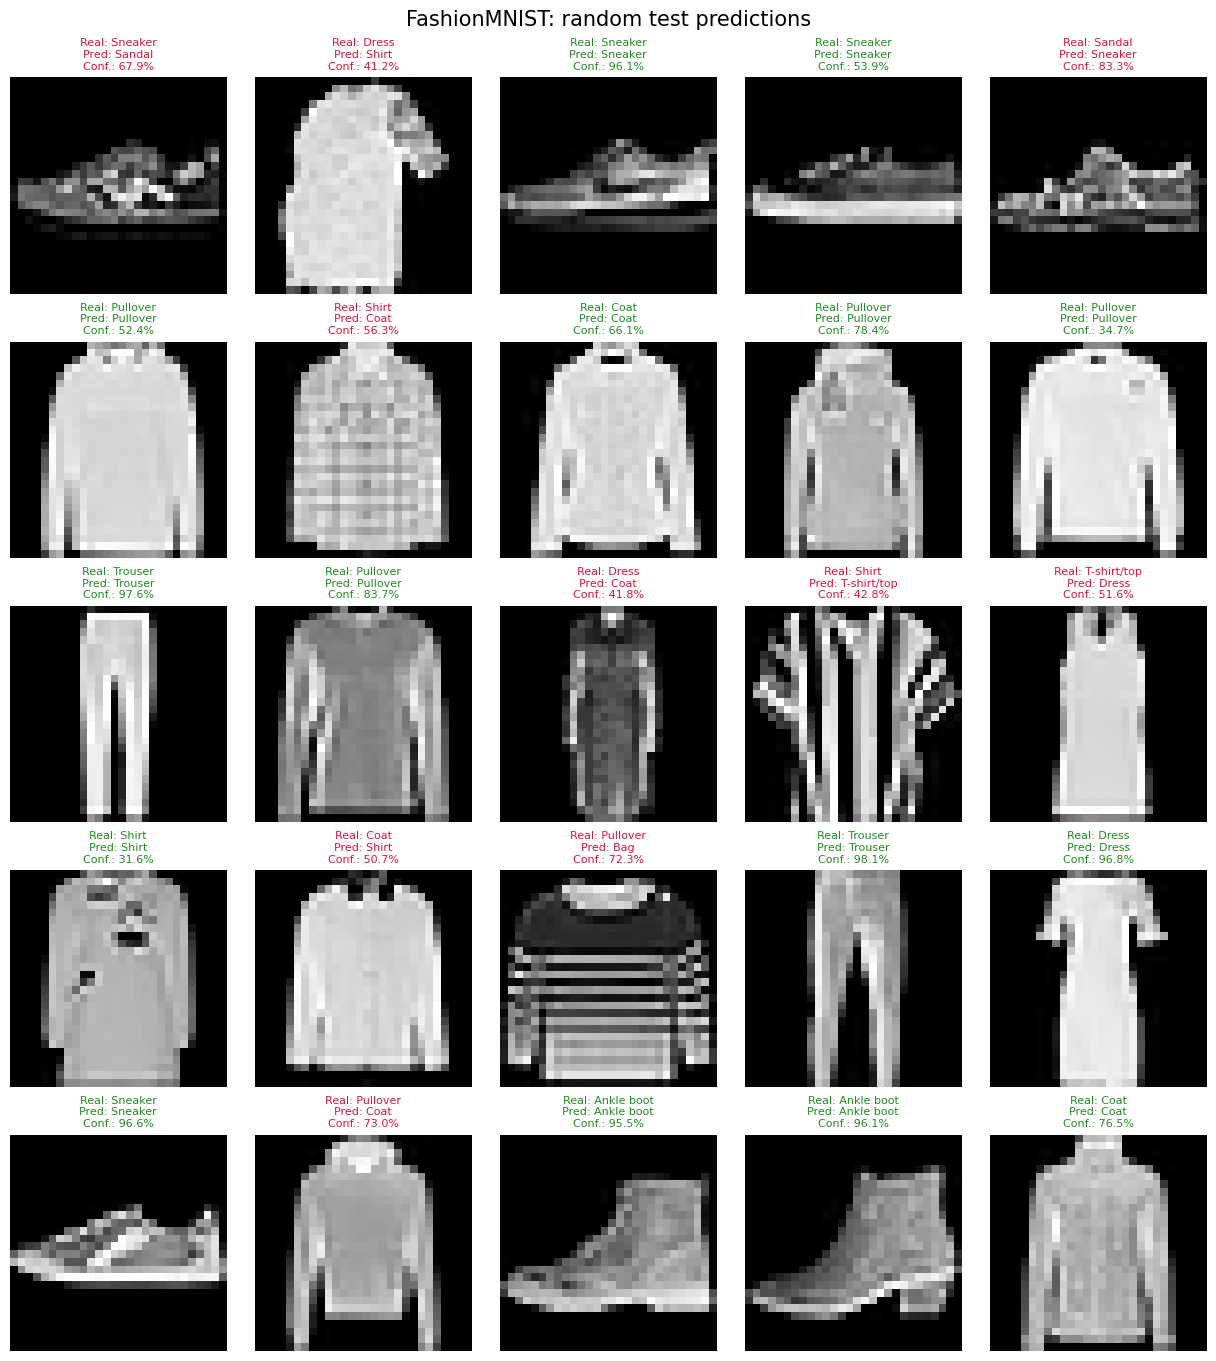

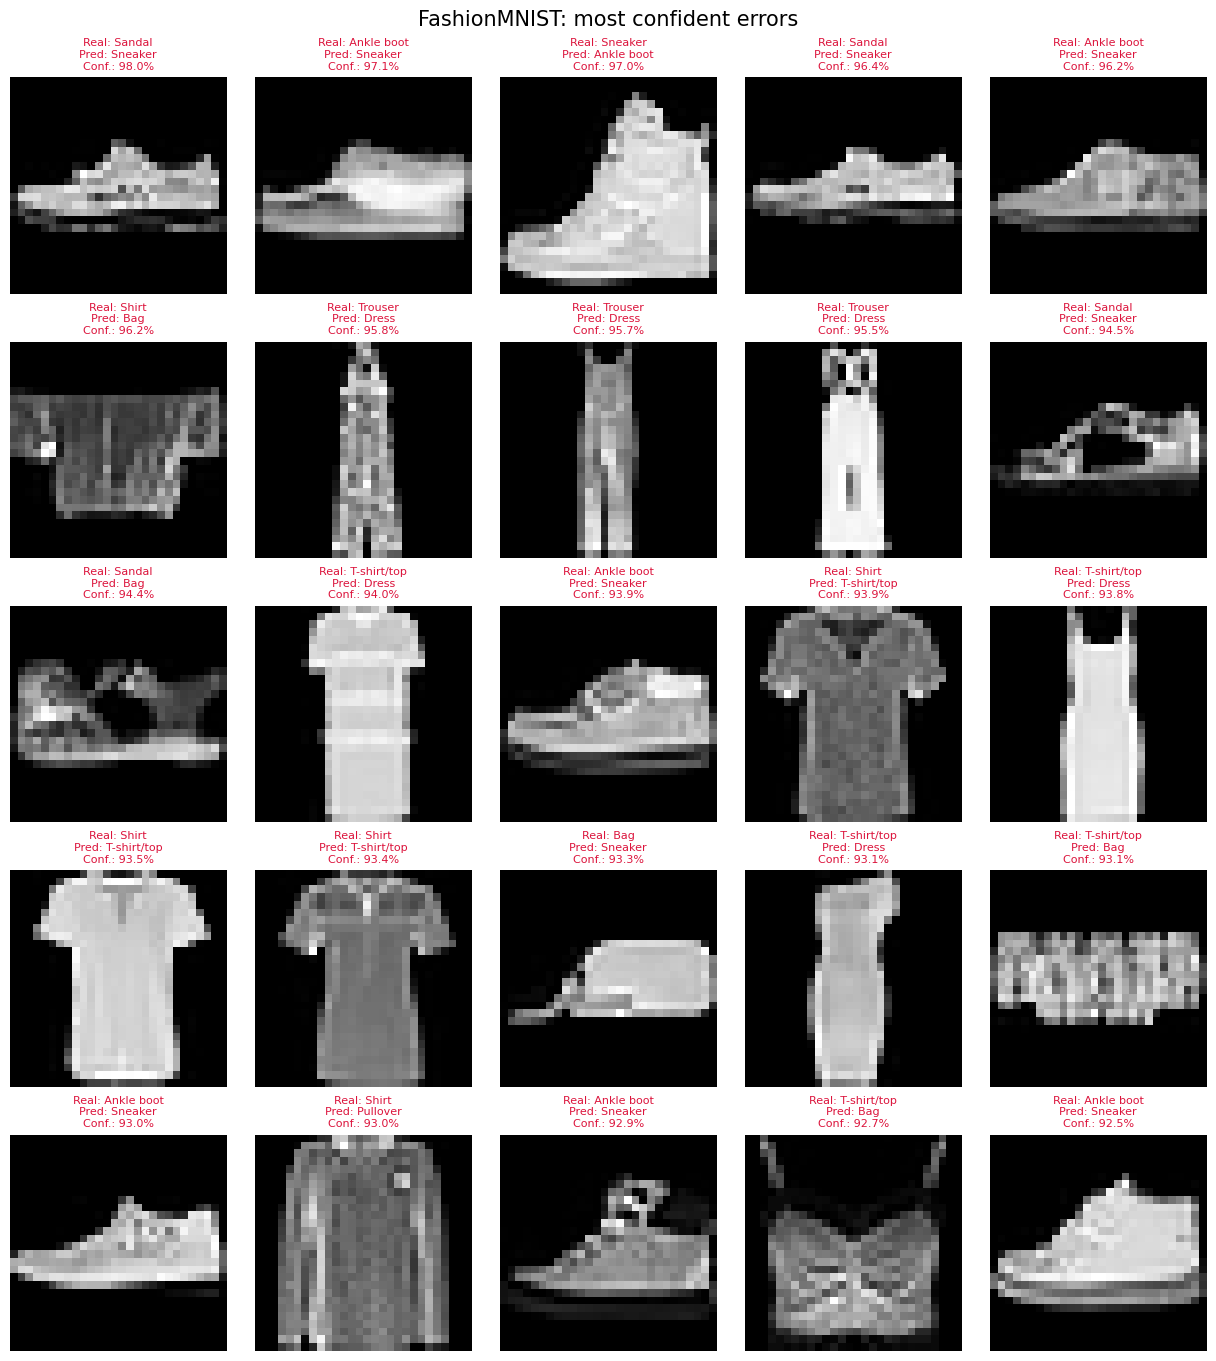

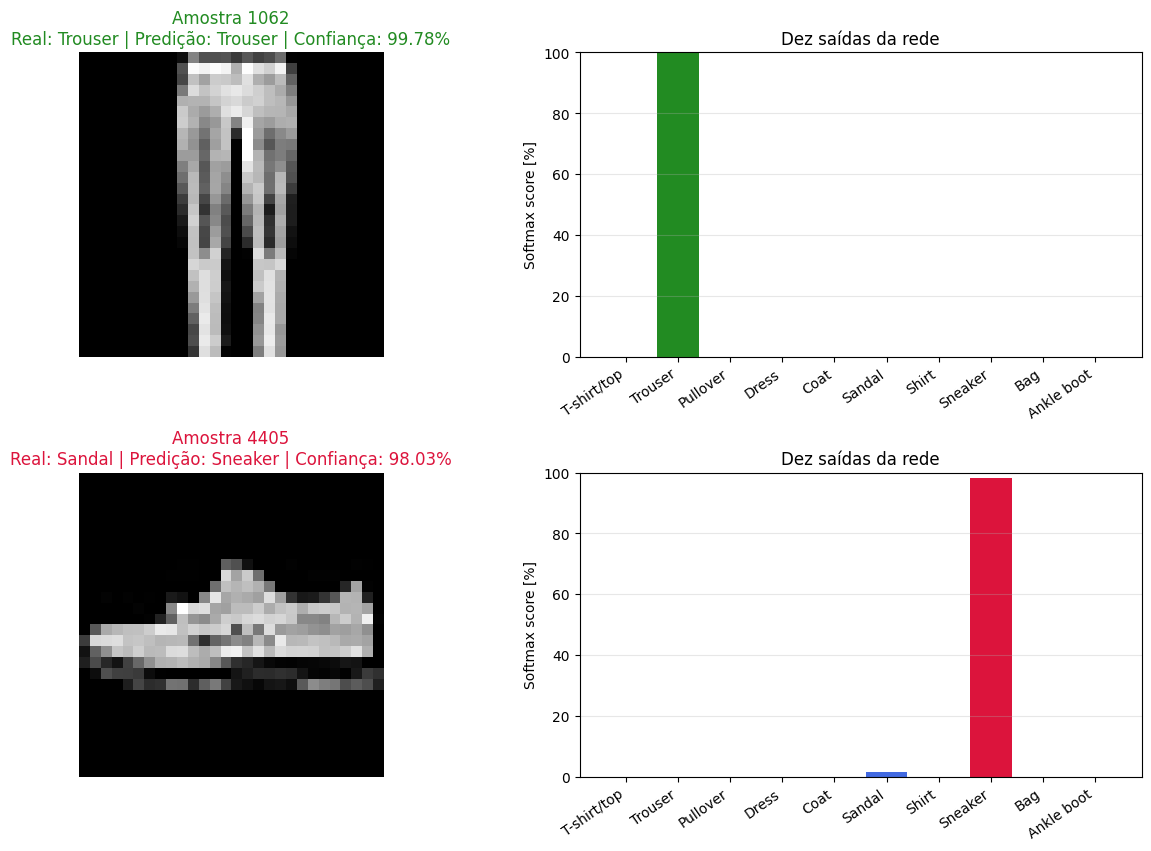

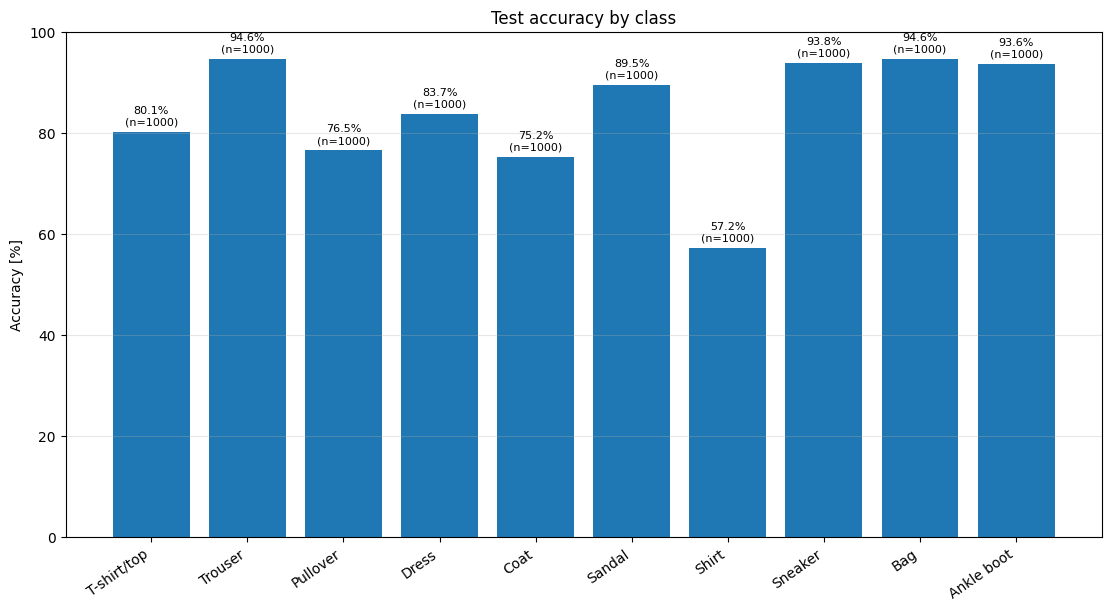

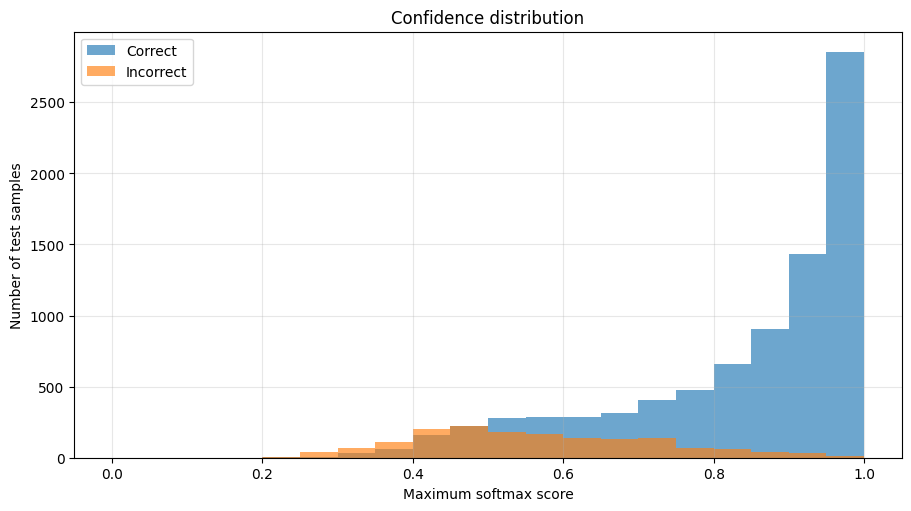


Figures and CSV saved in: C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results\FashionMNIST\prediction_visualizations


<Figure size 640x480 with 0 Axes>

In [15]:

%matplotlib inline

%run "visualize_trained_DRAMZI_KAN(1).py" --results-root "C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results" --dataset FashionMNIST --checkpoint best

PyTorch: 2.14.0+cu132
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4060
Loaded checkpoint: C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results\MNIST\best_validation_model.pt
Checkpoint epoch: 30

PREDICTION VISUALIZATION: MNIST
Checkpoint: best
Test examples: 10000
Correct: 9111
Incorrect: 889
Recomputed test accuracy: 91.11%
Note: the maximum softmax score is a model confidence score; it is not automatically a calibrated probability.


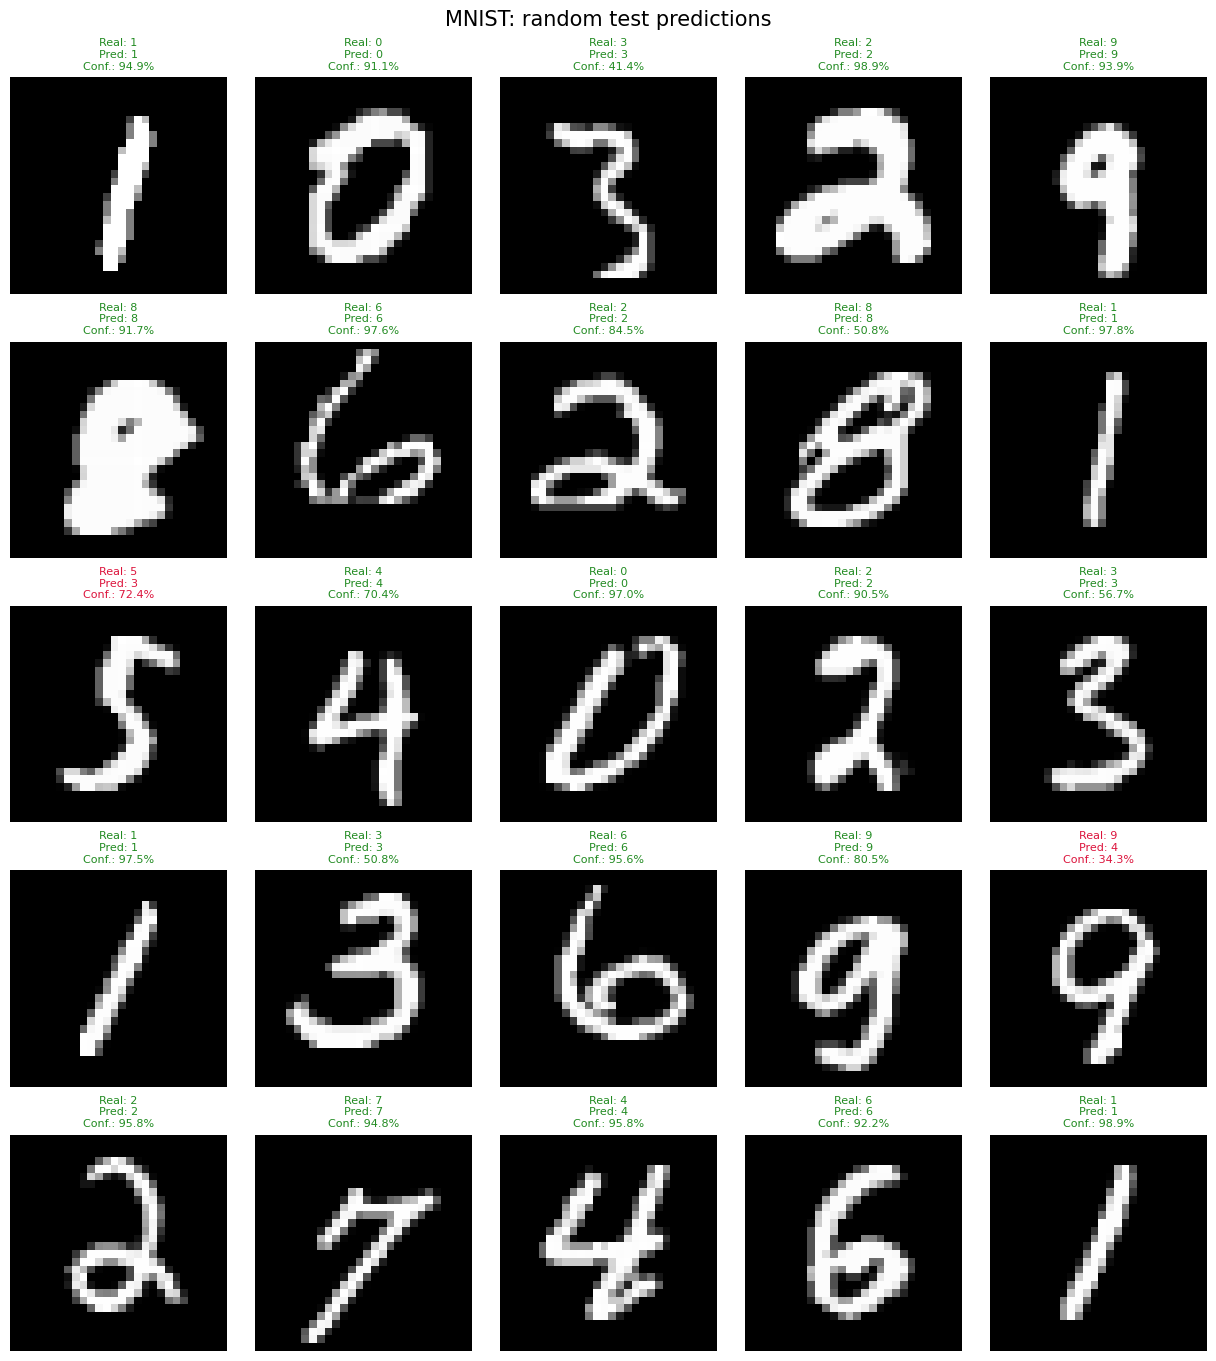

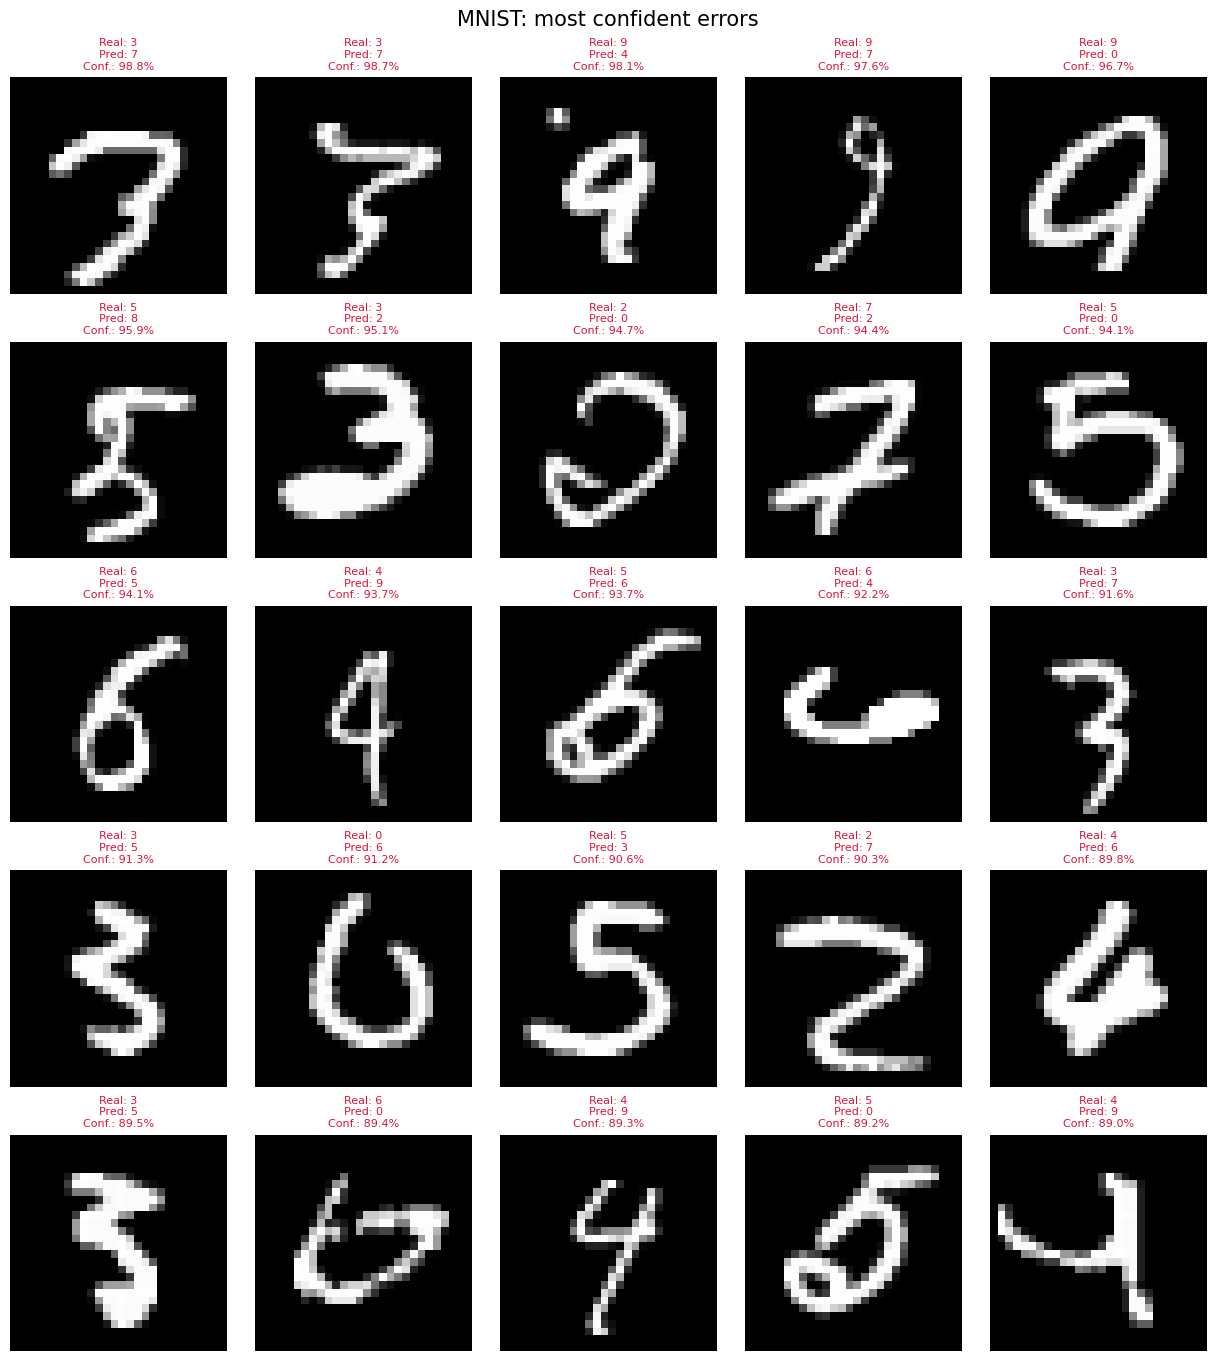

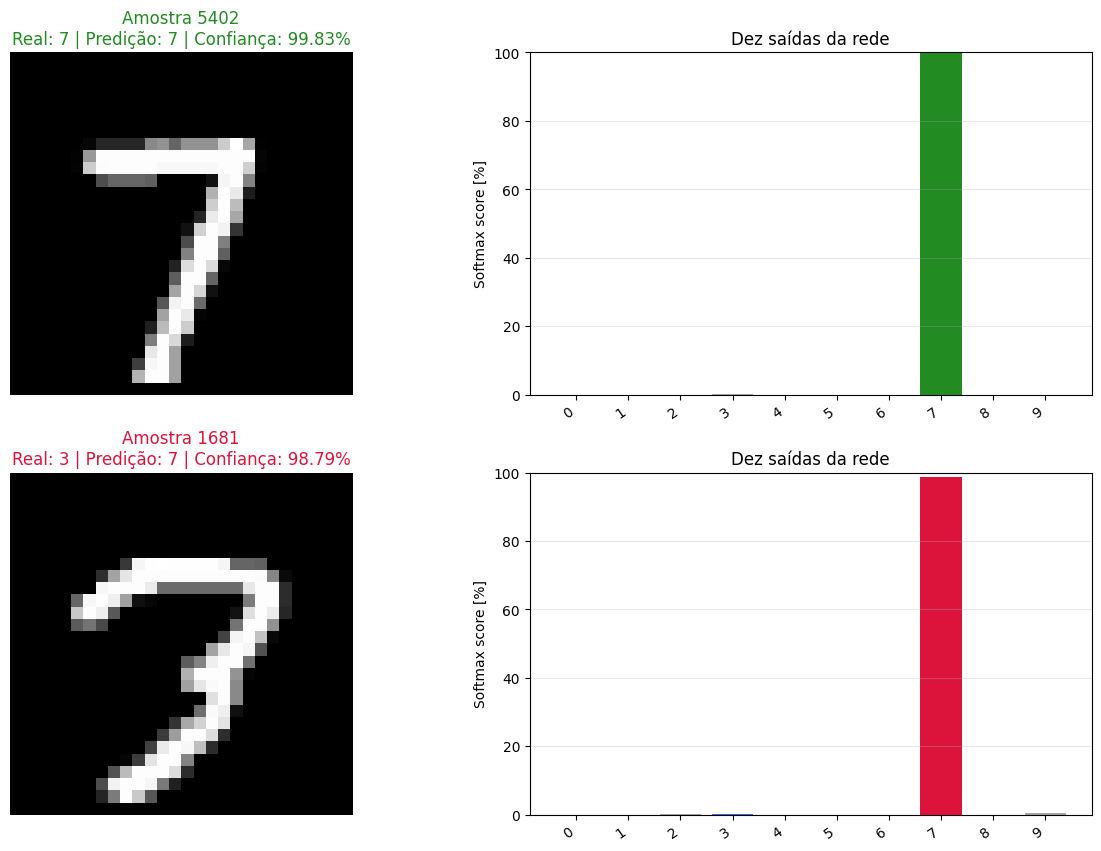

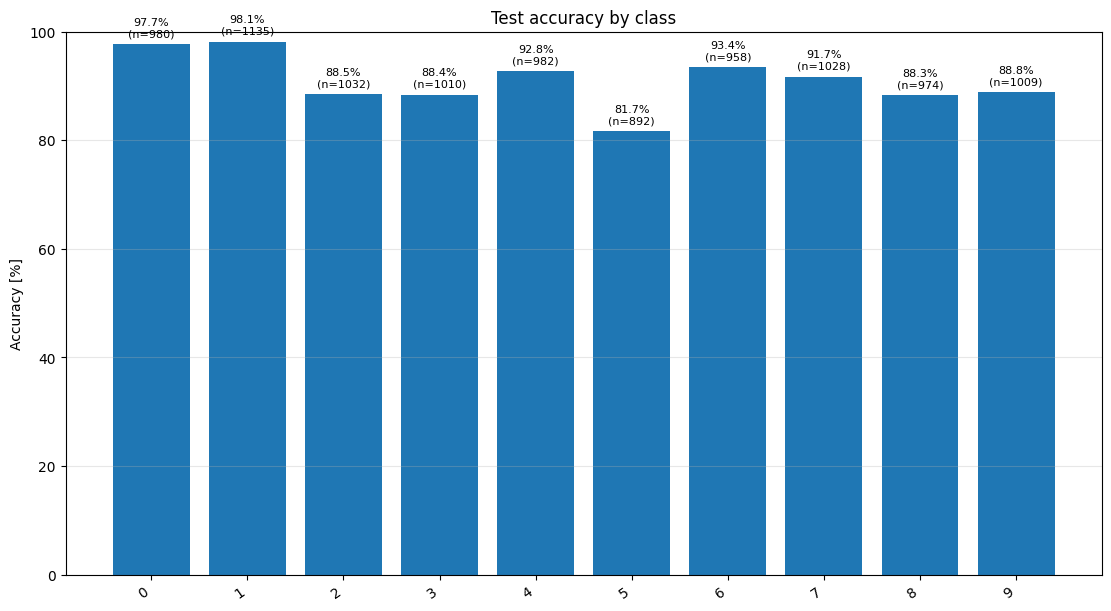

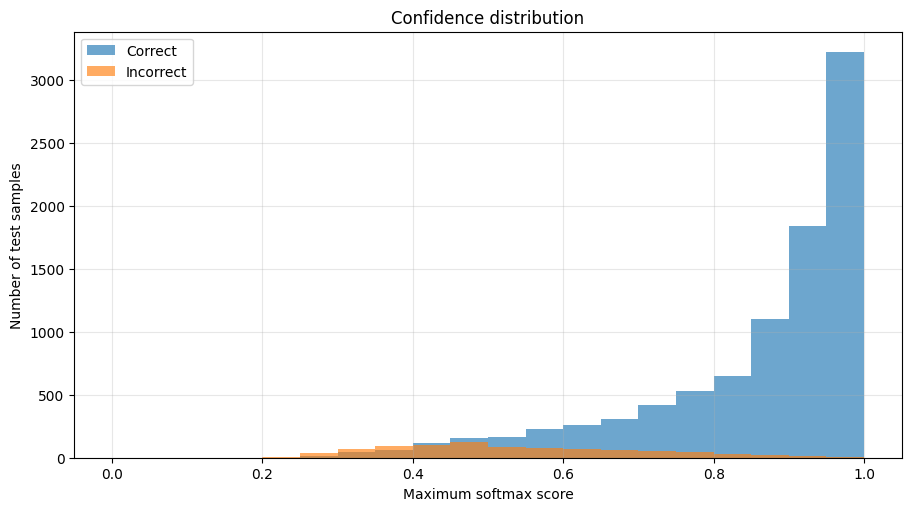


Figures and CSV saved in: C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results\MNIST\prediction_visualizations


<Figure size 640x480 with 0 Axes>

In [16]:
%run "visualize_trained_DRAMZI_KAN(1).py" --results-root "C:\Users\gson5\Downloads\PASTA DE ERICK\TCC\dramzi_photonic_kan_results" --dataset MNIST --checkpoint best